# Sensor Fusion, Kalman Filters and Tracking

> **Who is this for:** engineers who know a little Python and numpy and want to understand how robots, phones and cars combine several sensors into one reliable picture of the world.
>
> **What you will learn:**
> - **why** we fuse sensors (complementary strengths, redundancy) and the three **levels of fusion**: early (raw), mid (feature) and late (decision), compared on one toy dataset
> - **calibration** (intrinsic and extrinsic), **coordinate frames**, **rotation matrices** and **homogeneous transforms**
> - how to **project LiDAR points into a camera image** with the pinhole model, and what a small calibration error does
> - **time synchronization** and **latency compensation**
> - the **Kalman filter** from scratch (predict / update, the meaning of the **Kalman gain**), then an **extended Kalman filter (EKF)** that fuses radar (range, bearing) and LiDAR (x, y) to track a moving object, compared with each sensor alone
> - a **complementary filter** that fuses an accelerometer and a gyroscope into a tilt angle
> - **multi-object tracking**: data association with the **Hungarian algorithm**, track birth and death
> - a **particle filter** teaser for problems with several possible answers
> - **failure modes** (miscalibration, clock offset, a dead sensor) and **graceful degradation**
> - how **deep-learning fusion** (BEV fusion transformers) fits into this picture
>
> **Prerequisites:** [02_imu_activity_recognition_and_fall_detection.ipynb](02_imu_activity_recognition_and_fall_detection.ipynb) (IMU signals), [03_radar_fmcw_range_doppler_and_micro_doppler.ipynb](03_radar_fmcw_range_doppler_and_micro_doppler.ipynb) (radar measurements), [04_lidar_point_clouds_from_zero.ipynb](04_lidar_point_clouds_from_zero.ipynb) (LiDAR points), [Linear algebra](../14_Mathematics/01_linear_algebra.ipynb) and [Probability](../14_Mathematics/03_probability.ipynb) (Gaussian, variance).
>
> **Time needed:** about 2-3 hours. The notebook runs in well under a minute.
>
> **Runs on:** CPU, no API key, no internet. numpy, scipy, pandas, scikit-learn and matplotlib only. All sensor data is simulated inside the notebook.

## 0. Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment       # Hungarian algorithm
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

SEED = 11
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 90
T_START = time.time()
print("ready")

ready


## 1. Why fuse sensors?

**What it is.** **Sensor fusion** means combining data from several sensors to get an estimate that is better than any single sensor could give: more accurate, more complete, or more reliable.

**Simple analogy.** You cross a street using your **eyes** (good at where things are) and your **ears** (good at hearing a car coming from behind you). Each sense covers the other's blind spots, and if one is blocked (bright sun), the other still warns you.

Two main reasons:

| Reason | Meaning | Example |
|---|---|---|
| **Complementary strengths** | sensors measure different things, or are good in different conditions | camera reads a traffic light colour, radar measures speed in fog, LiDAR gives exact 3D shape |
| **Redundancy** | two sensors measure the same thing, so one can fail or be wrong without disaster | two independent ways to detect a pedestrian before emergency braking |

A third, quieter reason is **noise reduction**: averaging two independent noisy measurements reduces the error. For two measurements with variances $\sigma_1^2$ and $\sigma_2^2$, the best combination has variance

$$ \sigma^2_\text{fused} = \frac{1}{1/\sigma_1^2 + 1/\sigma_2^2} \le \min(\sigma_1^2, \sigma_2^2) $$

so the fused estimate is never worse than the better sensor, **if** both are unbiased and their errors are independent. Section 11 shows what happens when they are not.

In [2]:
sigma_radar, sigma_lidar = 0.8, 0.5            # metres, illustrative
w_r = (1 / sigma_radar**2) / (1 / sigma_radar**2 + 1 / sigma_lidar**2)   # weight = how much we trust radar
sigma_fused = np.sqrt(1 / (1 / sigma_radar**2 + 1 / sigma_lidar**2))
print(f"radar weight {w_r:.2f}, lidar weight {1-w_r:.2f}, fused sigma {sigma_fused:.3f} m")

# check by simulation
truth = 10.0
zr = truth + rng.normal(0, sigma_radar, 100_000)
zl = truth + rng.normal(0, sigma_lidar, 100_000)
fused = w_r * zr + (1 - w_r) * zl
print(f"simulated std: radar {zr.std():.3f}, lidar {zl.std():.3f}, fused {fused.std():.3f}")

radar weight 0.28, lidar weight 0.72, fused sigma 0.424 m
simulated std: radar 0.801, lidar 0.499, fused 0.424


## 2. Levels of fusion: early, mid and late

**What it is.** The question "**where** in the pipeline do we combine the sensors?"

```mermaid
flowchart LR
    subgraph Early[Early fusion: raw data]
      A1[Sensor A raw] --> E1[Concatenate]
      B1[Sensor B raw] --> E1
      E1 --> M1[One model] --> O1[Decision]
    end
    subgraph Mid[Mid fusion: features]
      A2[Sensor A raw] --> FA[Features A]
      B2[Sensor B raw] --> FB[Features B]
      FA --> E2[Concatenate] --> M2[One model] --> O2[Decision]
      FB --> E2
    end
    subgraph Late[Late fusion: decisions]
      A3[Sensor A raw] --> MA[Model A] --> PA[Probabilities A]
      B3[Sensor B raw] --> MB[Model B] --> PB[Probabilities B]
      PA --> C3[Combine votes] --> O3[Decision]
      PB --> C3
    end
```

| Level | Simple analogy | Good | Not so good |
|---|---|---|---|
| **Early (raw / low-level)** | mixing all ingredients before cooking | can learn any cross-sensor pattern | needs aligned data, lots of training data, and big models; one broken sensor confuses the whole model |
| **Mid (feature-level)** | each cook prepares one part, then one chef assembles the dish | compact, keeps cross-sensor interactions; the most common level in deep learning (for example BEV features) | features must be designed or learned per sensor |
| **Late (decision / object-level)** | each judge votes independently, then votes are combined | simple, modular, easy to drop a broken sensor, each sensor can be developed by a different team | loses information that only appears when sensors are combined |

**Toy demo.** Three simulated sensors watch the same event, which belongs to one of 4 classes:
- **Sensor A** gives a 40-sample vibration signal. Its **frequency** tells "class 0 or 1" apart from "class 2 or 3". The signal starts at a random **phase** (point in its cycle).
- **Sensor B** gives a 40-sample noise-like signal. Its **loudness** (amplitude) tells "class 0 or 2" apart from "class 1 or 3".
- **Sensor C** gives 2 weak numeric hints about the class.

No single sensor can tell all 4 classes apart, so fusion is required.

In [3]:
def make_multisensor(n, rng):
    y = rng.integers(0, 4, n)
    t = np.arange(40)
    freq = np.where(y < 2, 3, 5) / 40                     # cycles per sample (sensor A)
    phase = rng.uniform(0, 2 * np.pi, n)
    A = np.sin(2 * np.pi * freq[:, None] * t + phase[:, None]) + rng.normal(0, 0.8, (n, 40))
    amp = np.where(y % 2 == 0, 1.0, 1.5)                  # loudness (sensor B)
    B = amp[:, None] * rng.normal(0, 1, (n, 40))
    C = np.column_stack([y + rng.normal(0, 1.5, n), (y % 2) + rng.normal(0, 1.0, n)])
    return A, B, C, y

def features_A(A):          # hand-made features: energy at the two candidate frequencies
    spec = np.abs(np.fft.rfft(A, axis=1))
    return spec[:, [3, 5]]
def features_B(B):          # loudness
    return np.column_stack([B.std(axis=1), np.abs(B).mean(axis=1)])
def features_C(C):
    return C

A, B, C, y = make_multisensor(3000, rng)
idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.4, random_state=SEED, stratify=y)
print("sensor shapes:", A.shape, B.shape, C.shape, "| classes:", np.bincount(y))

sensor shapes: (3000, 40) (3000, 40) (3000, 2) | classes: [763 757 748 732]


In [4]:
def rf():
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=SEED, n_jobs=-1)

def evaluate(broken_B=False):
    """Accuracy of each fusion level. broken_B=True: at TEST time sensor B outputs zeros (it died)."""
    Bt = np.zeros_like(B) if broken_B else B
    feats = {"A": features_A(A), "B": features_B(B), "C": features_C(C)}
    feats_test = {"A": feats["A"], "B": features_B(Bt), "C": feats["C"]}
    res = {}
    # single sensors
    for s in "ABC":
        m = rf().fit(feats[s][idx_tr], y[idx_tr])
        res[f"sensor {s} alone"] = (m.predict(feats_test[s][idx_te]) == y[idx_te]).mean()
    # EARLY: raw data concatenated
    raw = np.hstack([A, B, C]); raw_t = np.hstack([A, Bt, C])
    m = rf().fit(raw[idx_tr], y[idx_tr])
    res["early (raw concat)"] = (m.predict(raw_t[idx_te]) == y[idx_te]).mean()
    # MID: features concatenated
    F = np.hstack([feats[s] for s in "ABC"]); Ft = np.hstack([feats_test[s] for s in "ABC"])
    m = rf().fit(F[idx_tr], y[idx_tr])
    res["mid (feature concat)"] = (m.predict(Ft[idx_te]) == y[idx_te]).mean()
    # LATE: one model per sensor, multiply the probabilities (add log-probabilities)
    use = "AC" if broken_B else "ABC"           # a health monitor tells us B is dead, so we drop its vote
    logp = 0
    for s in use:
        m = rf().fit(feats[s][idx_tr], y[idx_tr])
        logp = logp + np.log(m.predict_proba(feats_test[s][idx_te]) + 1e-3)
    res["late (product of votes)"] = (logp.argmax(axis=1) == y[idx_te]).mean()
    return res

t0 = time.time()
table = pd.DataFrame({"all sensors OK": evaluate(False), "sensor B dead at test time": evaluate(True)}).round(3)
print(table.to_string())
print(f"\n(chance level = 0.25; computed in {time.time()-t0:.1f} s)")

                         all sensors OK  sensor B dead at test time
sensor A alone                    0.498                       0.498
sensor B alone                    0.468                       0.254
sensor C alone                    0.496                       0.496
early (raw concat)                0.699                       0.382
mid (feature concat)              0.964                       0.503
late (product of votes)           0.953                       0.690

(chance level = 0.25; computed in 5.9 s)


How to read this table (exact numbers change with the seed, the pattern does not):

- **Single sensors** stay near 50%: each one only knows half of the answer.
- **Early fusion on raw samples** is clearly worse than mid fusion. A random forest cannot easily discover "frequency" from 40 raw samples with random phase. Deep networks can learn such features, but they need much more data.
- **Mid fusion** with good per-sensor features is the strongest when all sensors work.
- **Late fusion** is close to mid fusion here, because our sensors are **independent** given the class. When sensors interact (a pattern only visible in A and B together), late fusion loses.
- When **sensor B dies**, the early and mid models, trained with B always present, break badly. Late fusion simply drops B's vote and **degrades gracefully** to what A and C can still say. (Mid fusion can be made robust too, by randomly blanking sensors during training, called **sensor dropout** or modality dropout.)

## 3. Calibration, coordinate frames and transforms

### 3.1 Calibration

**What it is.** **Calibration** finds the numbers that link a sensor's raw output to the real world.

| Kind | Question it answers | Examples | How it is measured |
|---|---|---|---|
| **Intrinsic** | how does this sensor work inside? | camera focal length, image centre and lens distortion; IMU bias and scale; LiDAR beam angles | checkerboard images (camera); keeping the IMU still (bias); factory calibration (LiDAR) |
| **Extrinsic** | where is this sensor mounted relative to the others? | rotation and translation from LiDAR to camera, radar to car | targets seen by both sensors, or "targetless" methods that align edges, motion, or maps |
| **Temporal** | how do the clocks relate? | time offset between camera and LiDAR | hardware sync, or estimating the delay from motion |

**Simple analogy.** Intrinsic calibration is knowing your own glasses' prescription. Extrinsic calibration is knowing where each person in a team is standing, so that "the ball is 2 m to my left" can be translated into everyone else's view.

### 3.2 Coordinate frames

Each sensor reports data in **its own frame** (origin at the sensor, its own axis directions). A common robotics convention for vehicle frames: **x forward, y left, z up**. Cameras usually use an **optical frame**: **z forward** (into the scene), **x right**, **y down**.

### 3.3 Rotation matrices and homogeneous transforms

- A **rotation matrix** $R$ (3x3) turns a vector. It is **orthonormal**: $R^T R = I$, so its inverse is just its transpose, and $\det R = +1$.
- A **rigid transform** is a rotation plus a translation: $p' = R p + t$.
- A **homogeneous transform** packs both into one 4x4 matrix, so chains of transforms become matrix products:

$$ T = \begin{bmatrix} R & t \\ 0\;0\;0 & 1 \end{bmatrix}, \qquad \begin{bmatrix} p' \\ 1 \end{bmatrix} = T \begin{bmatrix} p \\ 1 \end{bmatrix} $$

**Naming rule that prevents most bugs:** write `T_a_b` for "the transform that takes points **from frame b into frame a**". Then frames chain like dominoes: `T_cam_lidar = T_cam_car @ T_car_lidar` (the inner names match and cancel).

In [5]:
def rot_x(a): c, s = np.cos(a), np.sin(a); return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])
def rot_y(a): c, s = np.cos(a), np.sin(a); return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])
def rot_z(a): c, s = np.cos(a), np.sin(a); return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])

def make_T(R, t):
    T = np.eye(4); T[:3, :3] = R; T[:3, 3] = t
    return T

def inv_T(T):
    """Inverse of a rigid transform, without a general matrix inverse: R^T and -R^T t."""
    R, t = T[:3, :3], T[:3, 3]
    return make_T(R.T, -R.T @ t)

def apply_T(T, pts):
    return pts @ T[:3, :3].T + T[:3, 3]

# Mounting positions on the car (illustrative numbers): x forward, y left, z up, origin on the ground under the rear axle
T_car_lidar = make_T(rot_z(np.deg2rad(0.0)), [1.2, 0.0, 1.9])            # LiDAR on the roof
# Camera: behind the windscreen, pitched 3 degrees down. R_opt turns car-style axes into optical axes.
R_opt = np.array([[0, -1, 0], [0, 0, -1], [1, 0, 0]])                     # optical x = -car y, y = -car z, z = car x
T_car_cam = make_T(rot_y(np.deg2rad(3.0)) @ R_opt.T, [1.6, 0.0, 1.4])   # takes camera-frame points into the car frame

T_cam_lidar = inv_T(T_car_cam) @ T_car_lidar                              # chain: lidar -> car -> camera
print("T_cam_lidar =\n", T_cam_lidar.round(3))
R = T_cam_lidar[:3, :3]
print("R^T R = I ?", np.allclose(R.T @ R, np.eye(3)), "| det R =", round(np.linalg.det(R), 6))
print("T @ inv(T) = I ?", np.allclose(T_cam_lidar @ inv_T(T_cam_lidar), np.eye(4)))

p_lidar = np.array([[10.0, 0.0, -1.9]])            # a point on the road 10 m in front of the LiDAR
print("point in lidar frame:", p_lidar[0], "-> in camera frame:", apply_T(T_cam_lidar, p_lidar)[0].round(3),
      "(z = distance in front of the camera, y > 0 = below the camera centre)")

T_cam_lidar =
 [[ 0.    -1.     0.     0.   ]
 [-0.052  0.    -0.999 -0.478]
 [ 0.999  0.    -0.052 -0.426]
 [ 0.     0.     0.     1.   ]]
R^T R = I ? True | det R = 1.0
T @ inv(T) = I ? True
point in lidar frame: [10.   0.  -1.9] -> in camera frame: [0.    0.896 9.66 ] (z = distance in front of the camera, y > 0 = below the camera centre)


## 4. Projecting LiDAR points into a camera image

**What it is.** To "paint" camera colours onto LiDAR points, or to give camera detections a depth, we draw each 3D point where the camera would see it.

**The pinhole camera model.** A point $(X, Y, Z)$ in the **camera frame** lands on pixel $(u, v)$:

$$ u = f_x \frac{X}{Z} + c_x, \qquad v = f_y \frac{Y}{Z} + c_y $$

$f_x, f_y$ are focal lengths in pixels and $(c_x, c_y)$ is the image centre. Together they form the **intrinsic matrix** $K$. Dividing by $Z$ is what makes far things look small. Real lenses add **distortion**, which calibration also corrects (we skip it here).

**Steps:** LiDAR frame -> camera frame (extrinsic `T_cam_lidar`) -> keep points with $Z > 0$ (in front of the camera) -> pixels (intrinsic K) -> keep pixels inside the image.

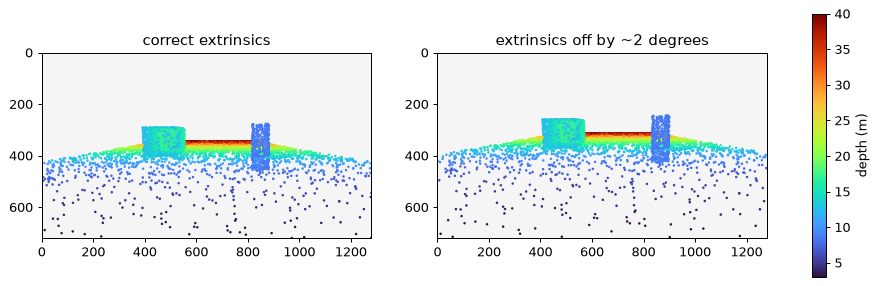

car centre moved by 35 pixels because of a 2 degree error


In [6]:
W_IMG, H_IMG = 1280, 720
K = np.array([[900.0, 0, W_IMG / 2], [0, 900.0, H_IMG / 2], [0, 0, 1]])

def project(pts_lidar, T_cam_lidar, K):
    pc = apply_T(T_cam_lidar, pts_lidar)
    front = pc[:, 2] > 0.5                              # only points in front of the camera
    uvw = pc[front] @ K.T
    uv = uvw[:, :2] / uvw[:, 2:3]                       # divide by depth
    inside = (uv[:, 0] >= 0) & (uv[:, 0] < W_IMG) & (uv[:, 1] >= 0) & (uv[:, 1] < H_IMG)
    return uv[inside], pc[front][inside, 2]

# A small synthetic LiDAR scene (in the LiDAR frame): road points, a car-sized box, a pedestrian-sized cylinder
road = np.column_stack([rng.uniform(3, 40, 4000), rng.uniform(-8, 8, 4000), np.full(4000, -1.9)])
def box_surface(center, size, n):
    p = rng.uniform(-0.5, 0.5, (n, 3)) * size
    face = rng.integers(0, 3, n)                        # push each point onto one face of the box
    p[np.arange(n), face] = np.sign(p[np.arange(n), face]) * size[face] / 2
    return p + center
car = box_surface(np.array([15.0, 2.5, -1.9 + 0.95]), np.array([4.5, 1.8, 1.5]), 1500)
ang = rng.uniform(0, 2 * np.pi, 400)
ped = np.column_stack([9 + 0.3 * np.cos(ang), -2 + 0.3 * np.sin(ang), rng.uniform(-1.9, -0.15, 400)])
scene = np.vstack([road, car, ped])

uv, depth = project(scene, T_cam_lidar, K)
# a 2-degree pitch + 1-degree yaw error (rotations about the camera's x and y axes): "someone bumped the sensor"
T_bad = make_T(rot_y(np.deg2rad(1.0)) @ rot_x(np.deg2rad(2.0)), [0, 0, 0]) @ T_cam_lidar
uv_bad, depth_bad = project(scene, T_bad, K)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (u_, d_), title in [(axes[0], (uv, depth), "correct extrinsics"), (axes[1], (uv_bad, depth_bad), "extrinsics off by ~2 degrees")]:
    sc = ax.scatter(u_[:, 0], u_[:, 1], c=d_, s=1, cmap="turbo", vmin=3, vmax=40)
    ax.set_xlim(0, W_IMG); ax.set_ylim(H_IMG, 0); ax.set_aspect("equal"); ax.set_title(title)
    ax.set_facecolor("whitesmoke")
plt.colorbar(sc, ax=axes, label="depth (m)"); plt.show()

uv_car, _ = project(car, T_cam_lidar, K); uv_car_bad, _ = project(car, T_bad, K)
print(f"car centre moved by {np.linalg.norm(uv_car.mean(0) - uv_car_bad.mean(0)):.0f} pixels because of a 2 degree error")

A 2 degree mistake moves the car's points by tens of pixels, so LiDAR depth would be painted onto the wrong object (the pedestrian's depth onto the background, for example). Small angles matter more than small translations, because the error grows with distance: $\text{error} \approx \text{distance} \times \text{angle (radians)}$, so 2 degrees at 30 m is about 1 m.

## 5. Time synchronization and latency compensation

**What it is.** Sensors run at different rates (for example camera 30 Hz, LiDAR 10 Hz, radar 20 Hz) and their data arrives with different **latencies** (delays between measuring and delivering). Fusion must compare measurements of the **same moment**.

**Simple analogy.** Two friends describe a running dog over the phone, but one has a 1-second delay. If you do not account for it, the dog seems to be in two places.

**How it is done.**
1. **Common clock.** Hardware sync with a shared time source: GPS **PPS** (pulse per second) signals or **PTP** (Precision Time Protocol, IEEE 1588) over Ethernet. Every message gets a timestamp of **when it was measured**, not when it arrived.
2. **Matching.** Pair each camera frame with the LiDAR scan closest in time, or better, **interpolate** between the two scans around it.
3. **Latency compensation.** If a measurement arrives late, **predict forward** with a motion model (the Kalman filter's predict step does exactly this), or keep a short history and re-run the filter from the measurement time.

A spinning LiDAR adds one more effect: one turn takes 100 ms, so the car moves during a scan (**motion distortion** or "rolling shutter"). It is corrected with the vehicle's motion, a step often called **deskewing**.

In [7]:
v = 20.0                                         # object speed in m/s (72 km/h)
def obj_pos(t): return v * t                     # 1-D position along the road

lidar_t = np.arange(0, 2, 0.10)                  # 10 Hz LiDAR timestamps
cam_t = np.arange(0, 2, 1 / 30) + 0.013          # 30 Hz camera, clocks offset by 13 ms
cam_t = cam_t[(cam_t > lidar_t[0]) & (cam_t < lidar_t[-1])]

nearest = lidar_t[np.abs(lidar_t[None, :] - cam_t[:, None]).argmin(axis=1)]
err_nearest = np.abs(obj_pos(nearest) - obj_pos(cam_t))
interp = np.interp(cam_t, lidar_t, obj_pos(lidar_t))       # linear interpolation between scans
err_interp = np.abs(interp - obj_pos(cam_t))

latency = 0.08                                   # radar data arrives 80 ms after it was measured
t_now = 1.0
z_radar = obj_pos(t_now - latency)               # what the radar says (about the past)
z_comp = z_radar + v * latency                   # predict forward with the known speed
print(pd.DataFrame({
    "method": ["nearest LiDAR scan", "interpolated LiDAR", "radar, no latency fix", "radar, latency compensated"],
    "mean position error (m)": [err_nearest.mean(), err_interp.mean(), abs(z_radar - obj_pos(t_now)), abs(z_comp - obj_pos(t_now))],
}).round(3).to_string(index=False))

                    method  mean position error (m)
        nearest LiDAR scan                    0.531
        interpolated LiDAR                    0.000
     radar, no latency fix                    1.600
radar, latency compensated                    0.000


## 6. The Kalman filter from scratch

**What it is.** A **Kalman filter** keeps a best guess of a hidden **state** (for example position and velocity) **and** how unsure it is about that guess (a **covariance**). It repeats two steps:

1. **Predict**: move the guess forward with a motion model. Uncertainty **grows** (the world could have changed).
2. **Update**: a measurement arrives. Blend prediction and measurement. Uncertainty **shrinks**.

**Simple analogy.** You walk through a dark room counting steps (predict: you know roughly where you are, but less sure with every step). Then you touch a wall (update: you are suddenly much more sure). How much you trust the wall vs your step count depends on how reliable each is.

**The Kalman gain** $K$ is that trust, between 0 and 1 in the simplest case:

$$ \hat x_\text{new} = \hat x_\text{pred} + K\,(z - \hat x_\text{pred}), \qquad K = \frac{P_\text{pred}}{P_\text{pred} + R} $$

- $P_\text{pred}$ = variance of the prediction, $R$ = variance of the measurement noise.
- Measurement very noisy ($R$ large): $K \to 0$, mostly keep the prediction.
- Prediction very unsure ($P$ large): $K \to 1$, mostly take the measurement.

**When to use / when not.** Ideal for linear models with Gaussian noise (it is then the best possible estimator). Nonlinear measurements need the **EKF** (section 7) or **UKF** (unscented Kalman filter); multi-modal problems need a **particle filter** (section 10).

### 6.1 Scalar example: estimating a constant

A thermometer reads a constant temperature with noise. The gain starts high (we know nothing) and falls as evidence piles up.

In [8]:
true_temp, R_meas = 21.5, 0.5**2                 # true value and measurement noise variance
x_hat, P = 15.0, 10.0**2                         # bad initial guess, very unsure
history = []
for k in range(25):
    # predict: the temperature does not change; add a tiny process noise Q
    P = P + 1e-4
    # update
    z = true_temp + rng.normal(0, np.sqrt(R_meas))
    K_gain = P / (P + R_meas)
    x_hat = x_hat + K_gain * (z - x_hat)
    P = (1 - K_gain) * P
    history.append((k, z, x_hat, K_gain, np.sqrt(P)))
h = pd.DataFrame(history, columns=["step", "measurement", "estimate", "gain K", "std of estimate"])
print(h.iloc[[0, 1, 2, 4, 9, 24]].round(3).to_string(index=False))

 step  measurement  estimate  gain K  std of estimate
    0       21.856    21.839   0.998            0.499
    1       20.529    21.185   0.499            0.353
    2       21.626    21.332   0.333            0.289
    4       21.505    21.480   0.200            0.224
    9       19.930    21.336   0.101            0.159
   24       21.598    21.439   0.043            0.104


### 6.2 Matrix form: tracking position and velocity in 1-D

With a state vector $x = [\text{position}, \text{velocity}]$ the same two steps become:

| Step | Equations | In words |
|---|---|---|
| Predict | $x \leftarrow F x$, $\; P \leftarrow F P F^T + Q$ | move by the motion model $F$, add process noise $Q$ |
| Innovation | $y = z - H x$, $\; S = H P H^T + R$ | how surprised we are, and how big a surprise is normal |
| Gain | $K = P H^T S^{-1}$ | trust in the measurement |
| Update | $x \leftarrow x + K y$, $\; P \leftarrow (I - K H) P$ | correct the guess, shrink the uncertainty |

$H$ picks out what the sensor measures (here: only position). The filter **infers velocity** although no sensor measures it.

RMSE raw measurements: 1.155 m
RMSE Kalman estimate:  0.680 m
velocity RMSE (never measured!): 0.538 m/s after the first 2 s


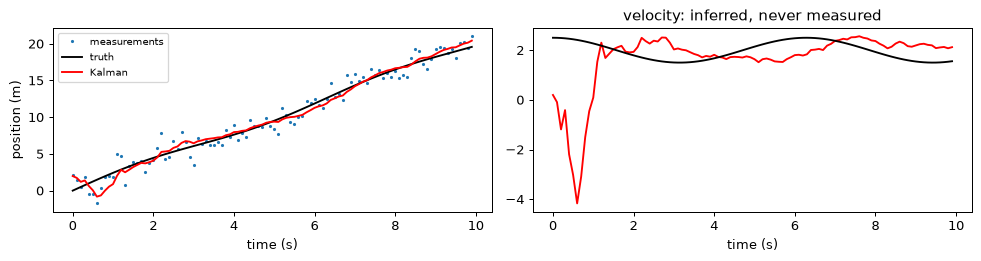

In [9]:
class KalmanFilter:
    """A plain linear Kalman filter."""
    def __init__(self, x0, P0):
        self.x, self.P = np.array(x0, float), np.array(P0, float)
    def predict(self, F, Q):
        self.x = F @ self.x
        self.P = F @ self.P @ F.T + Q
    def update(self, z, H, R):
        y = z - H @ self.x                                  # innovation
        S = H @ self.P @ H.T + R                            # innovation covariance
        K = self.P @ H.T @ np.linalg.inv(S)                 # Kalman gain
        self.x = self.x + K @ y
        self.P = (np.eye(len(self.x)) - K @ H) @ self.P
        return y, S

def cv_model(dt, q, dim=1):
    """Constant-velocity motion model. State per axis: [pos, vel]. q = acceleration noise variance."""
    F1 = np.array([[1, dt], [0, 1]])
    Q1 = q * np.array([[dt**4 / 4, dt**3 / 2], [dt**3 / 2, dt**2]])
    if dim == 1:
        return F1, Q1
    # 2-D: state [px, py, vx, vy]
    F = np.eye(4); F[0, 2] = F[1, 3] = dt
    Q = np.zeros((4, 4))
    for i in range(2):
        idx = [i, i + 2]
        Q[np.ix_(idx, idx)] = Q1
    return F, Q

dt, n = 0.1, 100
t = np.arange(n) * dt
true_pos = 2.0 * t + 0.5 * np.sin(t)                    # mostly constant speed, a little wobble
z = true_pos + rng.normal(0, 1.0, n)                    # noisy position sensor, sigma = 1 m
kf = KalmanFilter([0, 0], np.diag([10.0, 10.0]))
F, Q = cv_model(dt, q=0.5)
H, R1 = np.array([[1.0, 0.0]]), np.array([[1.0]])
est = []
for zi in z:
    kf.predict(F, Q); kf.update(np.array([zi]), H, R1); est.append(kf.x.copy())
est = np.array(est)
print(f"RMSE raw measurements: {np.sqrt(np.mean((z - true_pos)**2)):.3f} m")
print(f"RMSE Kalman estimate:  {np.sqrt(np.mean((est[:, 0] - true_pos)**2)):.3f} m")
print(f"velocity RMSE (never measured!): {np.sqrt(np.mean((est[20:, 1] - (2 + 0.5*np.cos(t[20:])))**2)):.3f} m/s after the first 2 s")

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(t, z, ".", ms=3, label="measurements"); ax[0].plot(t, true_pos, "k", label="truth"); ax[0].plot(t, est[:, 0], "r", label="Kalman")
ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("position (m)"); ax[0].legend(fontsize=8)
ax[1].plot(t, est[:, 1], "r"); ax[1].plot(t, 2 + 0.5 * np.cos(t), "k"); ax[1].set_title("velocity: inferred, never measured")
ax[1].set_xlabel("time (s)"); plt.tight_layout(); plt.show()

## 7. Fusing radar and LiDAR with an extended Kalman filter

**The problem.** One object moves on a gentle curve. Two sensors watch it from the origin:

| Sensor | Measures | Rate | Noise (illustrative) | Strength / weakness |
|---|---|---|---|---|
| **Radar** | range $r$ and bearing (angle) $\theta$ | 20 Hz | range 0.3 m, bearing 2 degrees | precise distance, poor sideways accuracy (2 degrees at 40 m is about 1.4 m) |
| **LiDAR** (after clustering) | object centre $x, y$ | 10 Hz | 0.6 m in x and y | same accuracy in all directions, slower |

**Why an EKF?** The radar measurement $h(x) = [\sqrt{p_x^2 + p_y^2},\ \operatorname{atan2}(p_y, p_x)]$ is **nonlinear** in the state. The **extended Kalman filter** linearises it around the current guess with the **Jacobian** (matrix of partial derivatives):

$$ H_\text{radar} = \begin{bmatrix} p_x/r & p_y/r & 0 & 0 \\ -p_y/r^2 & p_x/r^2 & 0 & 0 \end{bmatrix} $$

The LiDAR measurement is linear ($H$ just picks $p_x, p_y$), so it uses the normal update.

**Fusion is simple here:** one filter, one state. Measurements are processed **in time order**; for each one we predict to its timestamp and apply the update that matches its sensor. One detail: angle differences must be **wrapped** into $[-\pi, \pi]$, or a bearing of +179 degrees vs -179 degrees looks like a 358 degree error.

In [10]:
# ---- ground truth: constant speed, slowly turning ----
DT_TRUE = 0.01
T_END = 30.0
tt = np.arange(0, T_END, DT_TRUE)
heading = np.deg2rad(100) + 0.04 * tt                    # slowly turning left
speed = 8.0
truth_xy = np.column_stack([20 + np.cumsum(speed * np.cos(heading)) * DT_TRUE,
                            -30 + np.cumsum(speed * np.sin(heading)) * DT_TRUE])
def truth_at(t):
    return np.array([np.interp(t, tt, truth_xy[:, 0]), np.interp(t, tt, truth_xy[:, 1])])

RADAR_STD = np.array([0.3, np.deg2rad(2.0)])
LIDAR_STD = 0.6

def simulate_measurements(rng, lidar_yaw_error_deg=0.0, radar_clock_offset=0.0, lidar_dead_after=None):
    """List of (timestamp, sensor, z). Optional faults for section 11."""
    events = []
    for t in np.arange(0.05, T_END, 1 / 20):            # radar 20 Hz
        p = truth_at(t)
        z = np.array([np.hypot(*p), np.arctan2(p[1], p[0])]) + rng.normal(0, RADAR_STD)
        events.append((t + radar_clock_offset, "radar", z))   # a wrong clock = a wrong timestamp
    yaw = np.deg2rad(lidar_yaw_error_deg)
    Rerr = np.array([[np.cos(yaw), -np.sin(yaw)], [np.sin(yaw), np.cos(yaw)]])
    for t in np.arange(0.0, T_END, 1 / 10):             # lidar 10 Hz
        if lidar_dead_after is not None and t > lidar_dead_after:
            continue
        z = Rerr @ truth_at(t) + rng.normal(0, LIDAR_STD, 2)  # a mis-calibrated mount rotates every point
        events.append((t, "lidar", z))
    events.sort(key=lambda e: e[0])
    return events

events = simulate_measurements(np.random.default_rng(1))
print("number of measurements:", len(events), "| first three:")
for e in events[:3]:
    print("  ", round(e[0], 3), e[1], e[2].round(3))

number of measurements: 899 | first three:
   0.0 lidar [ 19.533 -29.289]
   0.05 radar [35.72  -0.949]
   0.1 radar [35.35  -1.018]


In [11]:
def wrap(a):
    return (a + np.pi) % (2 * np.pi) - np.pi

def radar_h(x):
    px, py = x[0], x[1]
    r = np.hypot(px, py)
    h = np.array([r, np.arctan2(py, px)])
    H = np.array([[px / r, py / r, 0, 0], [-py / r**2, px / r**2, 0, 0]])
    return h, H

H_LIDAR = np.array([[1.0, 0, 0, 0], [0, 1.0, 0, 0]])
R_LIDAR = np.eye(2) * LIDAR_STD**2
R_RADAR = np.diag(RADAR_STD**2)

def run_tracker(events, use=("radar", "lidar"), q=1.0, eval_dt=0.1):
    """EKF with a constant-velocity model. Returns estimates on a fixed time grid + NIS per sensor."""
    eval_times = np.arange(1.0, T_END, eval_dt)
    kf, t_last, out, nis, ei = None, None, [], {"radar": [], "lidar": []}, 0
    for (t, sensor, z) in events:
        if sensor not in use:
            continue
        # report estimates for evaluation times that come before this measurement
        while kf is not None and ei < len(eval_times) and eval_times[ei] <= t:
            F, _ = cv_model(eval_times[ei] - t_last, q, dim=2)
            out.append(F @ kf.x); ei += 1
        if kf is None:                                   # initialise from the first measurement
            p0 = z if sensor == "lidar" else z[0] * np.array([np.cos(z[1]), np.sin(z[1])])
            kf, t_last = KalmanFilter([p0[0], p0[1], 0, 0], np.diag([4, 4, 100, 100.0])), t
            continue
        F, Q = cv_model(t - t_last, q, dim=2)
        kf.predict(F, Q); t_last = t
        if sensor == "lidar":
            H, R_, y = H_LIDAR, R_LIDAR, z - H_LIDAR @ kf.x
        else:
            h, H = radar_h(kf.x); R_ = R_RADAR
            y = z - h; y[1] = wrap(y[1])
        S = H @ kf.P @ H.T + R_
        nis_value = y @ np.linalg.solve(S, y)            # normalised innovation squared
        nis[sensor].append(nis_value)                    # used in section 11 to spot faulty sensors
        K = kf.P @ H.T @ np.linalg.inv(S)
        kf.x = kf.x + K @ y
        kf.P = (np.eye(4) - K @ H) @ kf.P
    while ei < len(eval_times):                          # predict to the remaining evaluation times
        F, _ = cv_model(eval_times[ei] - t_last, q, dim=2); out.append(F @ kf.x); ei += 1
    est = np.array(out)
    truth = np.array([truth_at(t) for t in eval_times])
    rmse = np.sqrt(np.mean(np.sum((est[:, :2] - truth) ** 2, axis=1)))
    return dict(t=eval_times, est=est, truth=truth, rmse=rmse, nis={k: np.array(v) for k, v in nis.items()})

runs = {name: run_tracker(events, use) for name, use in
        [("radar only (EKF)", ("radar",)), ("lidar only (KF)", ("lidar",)), ("radar + lidar fused", ("radar", "lidar"))]}

# raw measurement error, for reference
raw_l = np.array([e[2] for e in events if e[1] == "lidar"]); tl = np.array([e[0] for e in events if e[1] == "lidar"])
raw_r = np.array([e[2][0] * np.array([np.cos(e[2][1]), np.sin(e[2][1])]) for e in events if e[1] == "radar"])
tr = np.array([e[0] for e in events if e[1] == "radar"])
rmse_raw = lambda pts, ts: np.sqrt(np.mean(np.sum((pts - np.array([truth_at(t) for t in ts]))**2, axis=1)))
print(f"raw radar points RMSE: {rmse_raw(raw_r, tr):.3f} m | raw lidar points RMSE: {rmse_raw(raw_l, tl):.3f} m")
for k, r_ in runs.items():
    print(f"{k:22s} position RMSE = {r_['rmse']:.3f} m")

raw radar points RMSE: 3.797 m | raw lidar points RMSE: 0.887 m
radar only (EKF)       position RMSE = 1.441 m
lidar only (KF)        position RMSE = 0.382 m
radar + lidar fused    position RMSE = 0.282 m


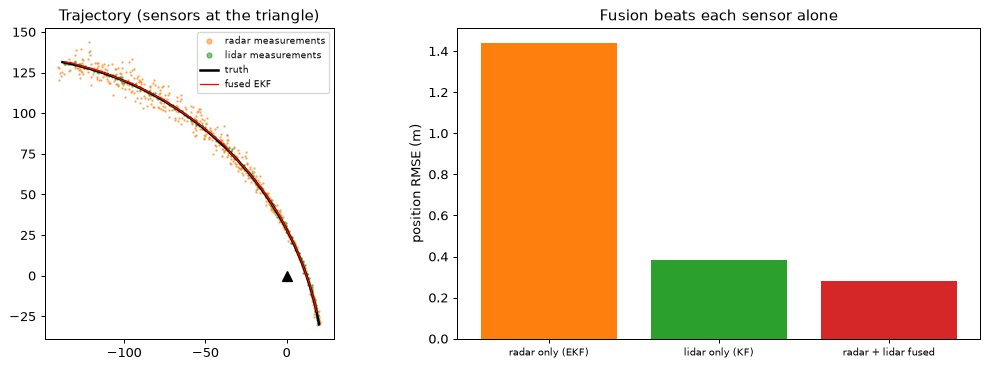

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot(raw_r[:, 0], raw_r[:, 1], ".", ms=2, c="tab:orange", alpha=0.5, label="radar measurements")
ax.plot(raw_l[:, 0], raw_l[:, 1], ".", ms=2, c="tab:green", alpha=0.6, label="lidar measurements")
ax.plot(*truth_xy.T, "k", lw=2, label="truth")
ax.plot(*runs["radar + lidar fused"]["est"][:, :2].T, "r", lw=1, label="fused EKF")
ax.plot(0, 0, "k^", ms=8); ax.set_aspect("equal"); ax.legend(fontsize=7, markerscale=4); ax.set_title("Trajectory (sensors at the triangle)")
names = list(runs)
axes[1].bar(names, [runs[k]["rmse"] for k in names], color=["tab:orange", "tab:green", "tab:red"])
axes[1].set_ylabel("position RMSE (m)"); axes[1].set_title("Fusion beats each sensor alone")
axes[1].tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

The fused filter has the lowest error. Radar pins down the **distance** and LiDAR pins down the **sideways** position, and the motion model smooths both. The Kalman gain does the weighting automatically from the noise values $R$. If those values are wrong (too optimistic about a sensor), fusion can actually make things worse, which is why tuning and checking the filter matters (section 11).

## 8. Complementary filter: tilt from an accelerometer and a gyroscope

**What it is.** An IMU (inertial measurement unit, see [notebook 02](02_imu_activity_recognition_and_fall_detection.ipynb)) has two sensors that can each estimate tilt (here **pitch**, the nose-up angle):

| | Gyroscope | Accelerometer |
|---|---|---|
| Measures | rotation **rate** (degrees per second) | acceleration, including **gravity** |
| Tilt from it | integrate the rate over time | angle of the gravity vector: $\theta = \operatorname{atan2}(-a_x, a_z)$ |
| Short term | smooth and accurate | noisy, disturbed by vibration and motion |
| Long term | **drifts** (a small bias adds up forever) | stable on average (gravity does not drift) |

**Simple analogy.** The gyroscope is a good short-term memory that slowly forgets; the accelerometer is a jumpy but honest friend. Trust the memory moment to moment, but keep nudging it toward the friend.

**How it works.** One line:

$$ \theta_k = \alpha\,(\theta_{k-1} + \omega_k\,\Delta t) + (1 - \alpha)\,\theta_{\text{acc},k}, \qquad \alpha \approx 0.98 $$

This is a **high-pass filter** on the gyro plus a **low-pass filter** on the accelerometer, which is where the name "complementary" comes from. It is cheap enough for any microcontroller. More advanced options: the **Mahony** and **Madgwick** filters (3-D orientation with quaternions) and an EKF.

pitch RMSE  gyro only:  25.90 deg | accel only:  8.87 deg | complementary:  1.45 deg


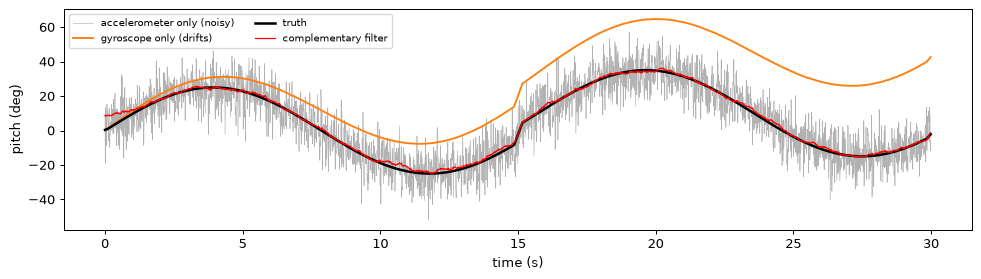

In [13]:
fs = 100; dt = 1 / fs; tt_imu = np.arange(0, 30, dt)
g = 9.81
pitch_true = np.deg2rad(25 * np.sin(0.4 * tt_imu) + 10 * (tt_imu > 15))
pitch_true = np.convolve(pitch_true, np.ones(30) / 30, mode="same")              # smooth the step a little
rate_true = np.gradient(pitch_true, dt)

gyro = rate_true + np.deg2rad(1.5) + rng.normal(0, np.deg2rad(0.5), len(tt_imu))  # bias 1.5 deg/s + noise
vib = rng.normal(0, 1.5, (len(tt_imu), 2))                                         # vibration in m/s^2
ax_m = -g * np.sin(pitch_true) + vib[:, 0]
az_m = g * np.cos(pitch_true) + vib[:, 1]

pitch_gyro = np.cumsum(gyro) * dt + pitch_true[0]          # gyro only: integrate the rate
pitch_acc = np.arctan2(-ax_m, az_m)                         # accelerometer only
alpha = 0.98
pitch_cf = np.zeros_like(tt_imu); pitch_cf[0] = pitch_acc[0]
for k in range(1, len(tt_imu)):
    pitch_cf[k] = alpha * (pitch_cf[k - 1] + gyro[k] * dt) + (1 - alpha) * pitch_acc[k]

rmse_deg = lambda e: np.rad2deg(np.sqrt(np.mean((e - pitch_true) ** 2)))
print(f"pitch RMSE  gyro only: {rmse_deg(pitch_gyro):6.2f} deg | accel only: {rmse_deg(pitch_acc):5.2f} deg | complementary: {rmse_deg(pitch_cf):5.2f} deg")

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(tt_imu, np.rad2deg(pitch_acc), c="tab:gray", lw=0.5, alpha=0.6, label="accelerometer only (noisy)")
ax.plot(tt_imu, np.rad2deg(pitch_gyro), c="tab:orange", label="gyroscope only (drifts)")
ax.plot(tt_imu, np.rad2deg(pitch_true), "k", lw=2, label="truth")
ax.plot(tt_imu, np.rad2deg(pitch_cf), "r", lw=1, label="complementary filter")
ax.set_xlabel("time (s)"); ax.set_ylabel("pitch (deg)"); ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

## 9. Multi-object tracking (MOT) basics

**What it is.** In real scenes there are many objects, missed detections, and false detections (**clutter**). A **multi-object tracker** keeps one Kalman filter per object (a **track**) and must decide, every frame, **which detection belongs to which track**. This is **data association**.

**Simple analogy.** A teacher on a school trip counts children every few minutes. Each child moved a little; the teacher matches "the child I see here" to "the child who was near here before". New children may join a group (birth), and someone may leave (death).

**How it works (a minimal SORT-style tracker).**

```mermaid
flowchart LR
    A[New frame: detections] --> B[Predict every track<br/>with its Kalman filter]
    B --> C[Cost matrix:<br/>distance track to detection]
    C --> D[Hungarian algorithm:<br/>best one-to-one matching]
    D --> E[Gate: reject pairs<br/>that are too far apart]
    E --> F[Matched: Kalman update]
    E --> G[Unmatched detection:<br/>new tentative track = birth]
    E --> H[Unmatched track:<br/>miss count + 1, delete after N misses = death]
```

- The **Hungarian algorithm** finds the matching with the smallest total cost in polynomial time. `scipy.optimize.linear_sum_assignment` implements it.
- **Gating** stops absurd matches (a detection 10 m away is not the same pedestrian).
- **Tentative vs confirmed tracks**: a new track becomes "confirmed" only after a few hits, which filters out clutter.

Camera-based trackers (SORT, DeepSORT, ByteTrack) are covered in [video analysis](../06_Computer_Vision/08_video_analysis.ipynb); the logic is the same for LiDAR and radar objects.

In [14]:
def simulate_mot(rng, n_frames=60, dt=0.1, p_detect=0.9, clutter_rate=1.5, noise=0.3):
    """4 objects in a 50 x 50 m area; object 3 appears late, object 2 leaves early."""
    starts = np.array([[5, 5], [5, 40], [45, 25], [25, 2]], float)
    vels = np.array([[4, 2.5], [5, -3], [-5, 0.5], [0.5, 5]], float)
    alive = [(0, n_frames), (0, n_frames), (0, 40), (20, n_frames)]       # frame range each object exists
    frames, truth = [], []
    for k in range(n_frames):
        dets, tr = [], {}
        for i in range(4):
            if alive[i][0] <= k < alive[i][1]:
                p = starts[i] + vels[i] * (k - alive[i][0]) * dt
                tr[i] = p
                if rng.random() < p_detect:
                    dets.append(p + rng.normal(0, noise, 2))
        for _ in range(rng.poisson(clutter_rate)):                        # false alarms
            dets.append(rng.uniform(0, 50, 2))
        frames.append(np.array(dets).reshape(-1, 2)); truth.append(tr)
    return frames, truth

class Track:
    _next_id = 0
    def __init__(self, z):
        self.kf = KalmanFilter([z[0], z[1], 0, 0], np.diag([1, 1, 25, 25.0]))
        self.hits, self.misses, self.confirmed = 1, 0, False
        self.id = Track._next_id; Track._next_id += 1
        self.history = [z.copy()]

def mot_step(tracks, dets, dt=0.1, gate=2.5, confirm_after=3, delete_after=3):
    F, Q = cv_model(dt, q=2.0, dim=2)
    for tr in tracks:
        tr.kf.predict(F, Q)
    matched_t, matched_d = set(), set()
    if tracks and len(dets):
        pred = np.array([tr.kf.x[:2] for tr in tracks])
        cost = np.linalg.norm(pred[:, None, :] - dets[None, :, :], axis=2)   # tracks x detections
        rows, cols = linear_sum_assignment(cost)
        for r, c_ in zip(rows, cols):
            if cost[r, c_] < gate:
                tracks[r].kf.update(dets[c_], H_LIDAR, np.eye(2) * 0.3**2)
                tracks[r].hits += 1; tracks[r].misses = 0
                tracks[r].confirmed |= tracks[r].hits >= confirm_after
                matched_t.add(r); matched_d.add(c_)
    for i, tr in enumerate(tracks):
        if i not in matched_t:
            tr.misses += 1
        tr.history.append(tr.kf.x[:2].copy())
    # death: delete tracks with too many misses (tentative tracks die after one miss)
    tracks = [tr for tr in tracks if tr.misses < (delete_after if tr.confirmed else 1)]
    # birth: every unmatched detection starts a tentative track
    tracks += [Track(dets[j]) for j in range(len(dets)) if j not in matched_d]
    return tracks

frames, truth = simulate_mot(np.random.default_rng(3))
tracks, ever_confirmed, log = [], {}, []
for k, dets in enumerate(frames):
    tracks = mot_step(tracks, dets)
    for tr in tracks:
        if tr.confirmed:
            ever_confirmed[tr.id] = tr
    log.append(dict(frame=k, true_objects=len(truth[k]), detections=len(dets),
                    confirmed_tracks=sum(tr.confirmed for tr in tracks), tentative=sum(not tr.confirmed for tr in tracks)))
print(pd.DataFrame(log).iloc[[0, 3, 10, 19, 25, 39, 45, 59]].to_string(index=False))
print("\nconfirmed track ids over the whole run:", sorted(ever_confirmed))

 frame  true_objects  detections  confirmed_tracks  tentative
     0             3           3                 0          3
     3             3           4                 3          1
    10             3           3                 3          1
    19             3           4                 3          2
    25             4           5                 4          3
    39             4           7                 4          3
    45             3           5                 3          2
    59             3           4                 3          1

confirmed track ids over the whole run: [0, 1, 2, 32, 38, 44, 87]


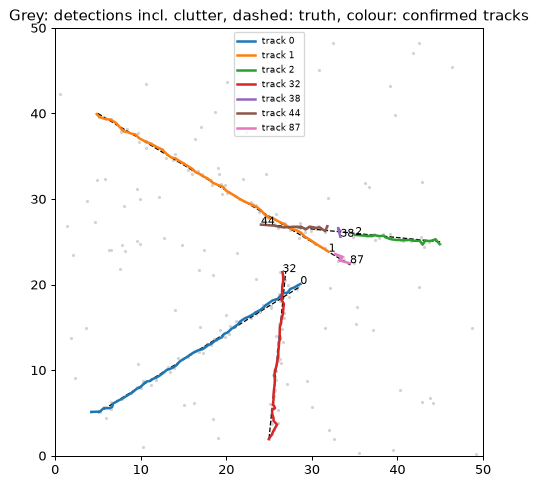

In [15]:
fig, ax = plt.subplots(figsize=(6, 5.5))
for k, dets in enumerate(frames):
    ax.plot(dets[:, 0], dets[:, 1], ".", c="lightgray", ms=3)
for i in range(4):
    pts = np.array([tr[i] for tr in truth if i in tr])
    ax.plot(pts[:, 0], pts[:, 1], "k--", lw=1)
for tid, tr in ever_confirmed.items():
    hst = np.array(tr.history)
    ax.plot(hst[:, 0], hst[:, 1], lw=2, label=f"track {tid}")
    ax.text(*hst[-1], str(tid), fontsize=9)
ax.set_xlim(0, 50); ax.set_ylim(0, 50); ax.set_aspect("equal"); ax.legend(fontsize=7)
ax.set_title("Grey: detections incl. clutter, dashed: truth, colour: confirmed tracks"); plt.tight_layout(); plt.show()

Things to notice:
- Clutter detections create tentative tracks that die after one miss, so they almost never become confirmed.
- The late object gets a new track a few frames after it appears (**birth**), and the track of the object that leaves is deleted after a few misses (**death**).
- Where two objects **cross paths**, this simple distance-only tracker gets confused: a track can end, jump to the other object, or restart with a new id. These are **ID switches** and **fragmentations**, the classic MOT errors. Metrics such as MOTA, IDF1 and HOTA count them. This is why the list of confirmed track ids is longer than the 4 true objects.

Real trackers add better costs (Mahalanobis distance, appearance features, IoU of boxes) and smarter association for crowded scenes (JPDA, multiple-hypothesis tracking).

## 10. Particle filter teaser

**What it is.** A **particle filter** represents the belief with many random guesses (**particles**) instead of one Gaussian. Each particle is moved with the motion model, weighted by how well it explains the measurement, and then particles are **resampled** (good ones copied, bad ones dropped).

**Simple analogy.** Send 1,000 scouts to every possible place. After each clue, scouts in places that do not fit the clue go home, and scouts in places that fit call friends.

**When to use it.** When the belief can have **several peaks** (more than one place fits the evidence) or the models are very nonlinear. A Kalman filter can only hold one peak. Cost: many particles, so more compute. Classic use: robot localisation in a known map.

**Demo.** A robot drives along a 30 m corridor with doors at 4 m, 11 m and 21 m. Its only sensor measures the **distance to the nearest door**. At first many positions fit, so the belief has several peaks; as the robot moves, only one position stays consistent.

true position 17.00 m | particle estimate 16.98 m +- 0.16 m


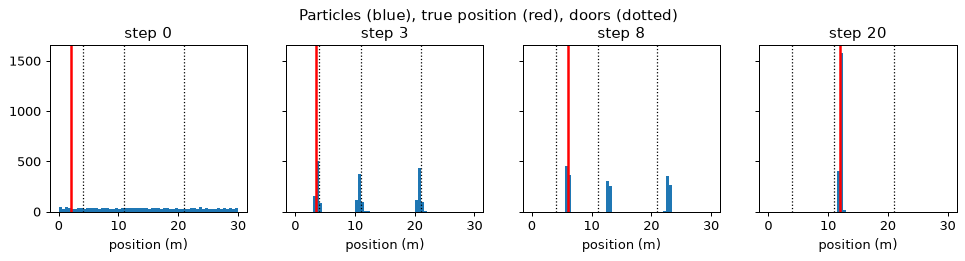

In [16]:
doors = np.array([4.0, 11.0, 21.0])
def door_dist(x): return np.min(np.abs(x[..., None] - doors), axis=-1)

prng = np.random.default_rng(5)
N = 2000
particles = prng.uniform(0, 30, N)                         # we have no idea where we are
x_true, step, meas_std = 2.0, 0.5, 0.3
snapshots = {}
for k in range(30):
    if k in (0, 3, 8, 20):
        snapshots[k] = particles.copy()
    x_true += step                                         # robot moves
    particles = particles + step + prng.normal(0, 0.1, N)  # move every particle (with motion noise)
    z = door_dist(np.array([x_true]))[0] + prng.normal(0, meas_std)
    w = np.exp(-0.5 * ((door_dist(particles) - z) / meas_std) ** 2) + 1e-12
    w /= w.sum()
    # systematic resampling
    positions = (prng.random() + np.arange(N)) / N
    particles = particles[np.minimum(np.searchsorted(np.cumsum(w), positions), N - 1)]
print(f"true position {x_true:.2f} m | particle estimate {particles.mean():.2f} m +- {particles.std():.2f} m")

fig, axes = plt.subplots(1, 4, figsize=(13, 2.4), sharey=True)
for ax, (k, p) in zip(axes, snapshots.items()):
    ax.hist(p, bins=60, range=(0, 30), color="tab:blue")
    for d in doors: ax.axvline(d, c="k", ls=":", lw=1)
    ax.axvline(2.0 + 0.5 * k, c="r", lw=2)
    ax.set_title(f"step {k}"); ax.set_xlabel("position (m)")
plt.suptitle("Particles (blue), true position (red), doors (dotted)", y=1.05); plt.show()

## 11. Failure modes and graceful degradation

Fusion assumes each sensor is **calibrated**, **time-aligned** and **working**. Real systems break these assumptions. We reuse the radar + LiDAR tracker from section 7 and inject faults:

| Fault | What happens in real life | Simulated as |
|---|---|---|
| **Miscalibration** | a sensor gets bumped, or the mount bends with heat | LiDAR extrinsic yaw off by 3 degrees |
| **Clock offset / drift** | clocks not synced, or slowly drifting apart | radar timestamps 0.25 s late |
| **Sensor failure** | cable, power, dirt, snow, software crash | LiDAR stops sending after 15 s |

**Detecting trouble: the NIS test.** The **normalised innovation squared**, $\text{NIS} = y^T S^{-1} y$, measures how surprising a measurement is compared with what the filter expected. If the filter and sensor are healthy, NIS follows a chi-square distribution whose average equals the measurement dimension (here 2). An average NIS far above 2 means something is wrong: a sensor is biased, timing is off, or the filter's noise values are mis-tuned. Measurements with NIS above a threshold (9.21 is the 99% point for 2 dimensions) can be **gated** (ignored).

In [17]:
cases = {
    "healthy": dict(),
    "lidar yaw miscalibrated 3 deg": dict(lidar_yaw_error_deg=3.0),
    "radar clock 0.25 s late": dict(radar_clock_offset=0.25),
    "lidar dead after 15 s": dict(lidar_dead_after=15.0),
}
rows = []
for name, fault in cases.items():
    ev = simulate_measurements(np.random.default_rng(1), **fault)
    fused = run_tracker(ev)
    radar_only = run_tracker(ev, use=("radar",))
    lidar_only = run_tracker(ev, use=("lidar",))
    rows.append({"case": name, "fused RMSE": fused["rmse"], "radar-only RMSE": radar_only["rmse"],
                 "lidar-only RMSE": lidar_only["rmse"],
                 "mean NIS radar": fused["nis"]["radar"].mean(), "mean NIS lidar": fused["nis"]["lidar"].mean()})
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("\n(healthy mean NIS should be close to 2)")

                         case  fused RMSE  radar-only RMSE  lidar-only RMSE  mean NIS radar  mean NIS lidar
                      healthy        0.28             1.44             0.38            1.98            2.28
lidar yaw miscalibrated 3 deg        5.12             1.44             5.40            3.40            3.14
      radar clock 0.25 s late        1.63             2.80             0.38            2.63            9.65
        lidar dead after 15 s        1.41             1.44            12.49            2.01            2.27

(healthy mean NIS should be close to 2)


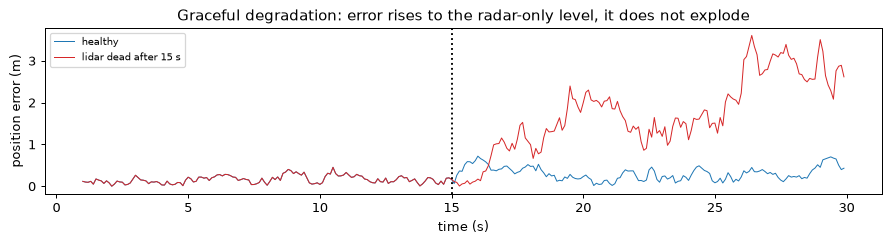

In [18]:
# What does the fused filter do when the LiDAR dies? Its uncertainty grows, but it keeps tracking with radar.
ev = simulate_measurements(np.random.default_rng(1), lidar_dead_after=15.0)
r_dead = run_tracker(ev)
err = np.linalg.norm(r_dead["est"][:, :2] - r_dead["truth"], axis=1)
r_ok = runs["radar + lidar fused"]
err_ok = np.linalg.norm(r_ok["est"][:, :2] - r_ok["truth"], axis=1)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(r_ok["t"], err_ok, c="tab:blue", lw=0.8, label="healthy")
ax.plot(r_dead["t"], err, c="tab:red", lw=0.8, label="lidar dead after 15 s")
ax.axvline(15, c="k", ls=":"); ax.set_xlabel("time (s)"); ax.set_ylabel("position error (m)"); ax.legend(fontsize=8)
ax.set_title("Graceful degradation: error rises to the radar-only level, it does not explode"); plt.tight_layout(); plt.show()

Lessons from the table and the plot:

- **Miscalibration** puts a **bias** into one sensor. The error grows with distance (3 degrees at 100 m is about 5 m), so the fused result can be **worse than the healthy sensor alone**. This is the warning from section 1: fusion only helps if each sensor is unbiased.
- **Clock offset** makes the radar report where the object **was**. For a moving object this acts like a position bias along the direction of motion, and again fusion becomes worse than the better sensor alone.
- **NIS rises above 2** in both fault cases, so the filter can tell that "something is inconsistent". But look closely: with the late radar clock, the **LiDAR** NIS jumps, because the frequent radar updates dragged the estimate and the correct LiDAR now looks surprising. **NIS tells you that sensors disagree, not which one is wrong.** Blindly gating the "surprising" sensor would throw away the good one. Finding the culprit needs a third opinion (another sensor, a map, a calibration target) or per-sensor self-checks.
- **Sensor failure** is handled gracefully by a filter that processes whatever arrives: the error rises to the radar-only level instead of crashing. The system must still **notice** the silence (a watchdog on message rates) and tell the planner to drive more carefully, for example slower.

**Graceful degradation checklist**

| Practice | Why |
|---|---|
| Health monitoring per sensor (message rate, NIS, self-tests) | detect a dead or lying sensor quickly |
| Gating and robust updates | one crazy measurement must not ruin the state |
| Online calibration checks (for example comparing LiDAR edges with camera edges) | catch drift before it causes harm |
| Hardware time sync (PTP / PPS) and timestamp-at-measurement | avoid the clock-offset bias |
| Sensor dropout during training of learned fusion models | the model must still work when one input is missing |
| Defined fallback behaviours ("minimal risk condition") | the system knows what to do with fewer sensors |

## 12. Deep-learning fusion (conceptual)

Filters fuse **objects or measurements** with hand-written models. Modern perception stacks also fuse **inside neural networks**, usually at the **mid (feature) level**.

**BEV fusion in one picture.**

```mermaid
flowchart LR
    C[Camera images] --> CE[Image backbone] --> LIFT[Lift to BEV<br/>predict depth or use attention]
    L[LiDAR points] --> LE[Voxel / pillar backbone] --> LB[LiDAR BEV features]
    R[Radar points] --> RE[Small point encoder] --> RB[Radar BEV features]
    LIFT --> F[Fuse in a shared BEV grid<br/>concatenate + conv, or cross-attention]
    LB --> F
    RB --> F
    F --> H1[3D detection]
    F --> H2[Map segmentation]
    F --> H3[Tracking / prediction]
```

| Idea | What it does | Example names (as of late 2026, a fast-moving area) |
|---|---|---|
| **Shared BEV grid** | every sensor's features are moved into the same top-down grid, so fusion is just stacking channels | BEVFusion (MIT, 2022), BEVFusion (Peking Univ. / Alibaba, 2022) |
| **Cross-attention fusion** | a transformer lets queries (for example candidate objects) look at features from all sensors | TransFusion (2022), BEVFormer (camera-only, 2022) |
| **Point painting** | add camera segmentation scores to each LiDAR point before a LiDAR detector (early/mid fusion) | PointPainting (2020) |
| **End-to-end driving models** | perception, prediction and planning trained together from multi-sensor input | various research and industry systems |

**Learned fusion vs filters.**

| | Kalman-style filters | Learned (deep) fusion |
|---|---|---|
| Needs training data | no (needs noise models) | yes, a lot, with labels |
| Explainable / certifiable | yes, every number has meaning | harder |
| Handles raw, high-dimensional data (images) | no | yes |
| Typical role | tracking, localisation, state estimation | detection, segmentation, scene understanding |

In practice they **work together**: a network detects objects in each frame, and a Kalman-filter tracker (section 9) links them over time.

## 13. Recap / cheat sheet

| Topic | Key idea | One-line formula or tool |
|---|---|---|
| Why fuse | complementary strengths + redundancy | $\sigma^2_\text{fused} = (1/\sigma_1^2 + 1/\sigma_2^2)^{-1}$ |
| Fusion levels | early (raw), mid (features), late (decisions) | late = multiply per-sensor probabilities |
| Calibration | intrinsic (inside), extrinsic (mounting), temporal (clocks) | checkerboards, targets, targetless methods |
| Transforms | `T_a_b` maps frame b into frame a | $T = [R\ t; 0\ 1]$, inverse $= [R^T\ \ {-R^T t}]$ |
| Projection | pinhole camera | $u = f_x X/Z + c_x$ |
| Time sync | measure-time stamps, interpolate, predict forward | PTP, PPS |
| Kalman filter | predict (uncertainty grows), update (shrinks) | $K = P H^T (H P H^T + R)^{-1}$ |
| EKF | linearise a nonlinear sensor with its Jacobian | radar range/bearing |
| Complementary filter | gyro short term + accelerometer long term | $\theta = \alpha(\theta + \omega\Delta t) + (1-\alpha)\theta_\text{acc}$ |
| MOT | predict, associate, update, birth / death | `scipy.optimize.linear_sum_assignment` |
| Particle filter | many weighted guesses, handles several peaks | predict, weight, resample |
| Health checks | NIS near the measurement dimension | gate at chi-square 99% |

## 14. Interview questions

1. **Early vs late fusion: when do you pick which?** Early/mid fusion when cross-sensor patterns matter and you have lots of aligned training data; late fusion when you want modularity, separate teams per sensor, and easy handling of a failed sensor.
2. **What does the Kalman gain represent?** How much to trust the new measurement relative to the prediction; it is large when the prediction is uncertain and small when the measurement is noisy.
3. **Why do we need an EKF for radar?** Range and bearing are nonlinear functions of x and y; the EKF linearises them with the Jacobian at the current estimate.
4. **What is `T_cam_lidar` and how do you invert a rigid transform cheaply?** It maps LiDAR-frame points into the camera frame; the inverse is $[R^T, -R^T t]$.
5. **A 1 degree extrinsic error: how bad is it?** About distance x 0.0175, so 0.5 m at 30 m: enough to paint depth on the wrong object.
6. **How do you handle a sensor that is 100 ms late?** Timestamp at measurement time, then predict the state forward (or keep a buffer and replay the filter from that time).
7. **Why combine a gyro and an accelerometer for tilt?** The gyro is smooth but drifts; the accelerometer is noisy but drift-free; a complementary or Kalman filter keeps the best of both.
8. **What does the Hungarian algorithm do in tracking?** It finds the one-to-one track-to-detection assignment with minimum total cost; gating then rejects implausible pairs.
9. **When does a particle filter beat a Kalman filter?** When the belief has several peaks or the models are strongly nonlinear or non-Gaussian, for example global localisation.
10. **How would you detect a miscalibrated sensor online?** Monitor its NIS (or residuals) over time; a consistently high or biased innovation signals a calibration or timing problem.

## 15. Further reading

- R. E. Kalman, "A New Approach to Linear Filtering and Prediction Problems", *Journal of Basic Engineering*, 1960.
- G. Welch and G. Bishop, "An Introduction to the Kalman Filter", UNC Chapel Hill technical report TR 95-041 (gentle introduction).
- S. Thrun, W. Burgard and D. Fox, *Probabilistic Robotics*, MIT Press, 2005 (Kalman, EKF, particle filters, SLAM).
- Y. Bar-Shalom, X. R. Li and T. Kirubarajan, *Estimation with Applications to Tracking and Navigation*, Wiley, 2001 (NIS, gating, tracking).
- H. W. Kuhn, "The Hungarian Method for the Assignment Problem", *Naval Research Logistics Quarterly*, 1955.
- A. Bewley et al., "Simple Online and Realtime Tracking" (SORT), ICIP 2016, arXiv:1602.00763.
- S. O. H. Madgwick, "An efficient orientation filter for inertial and inertial/magnetic sensor arrays", technical report, 2010; R. Mahony, T. Hamel and J.-M. Pflimlin, "Nonlinear Complementary Filters on the Special Orthogonal Group", *IEEE TAC*, 2008.
- Z. Zhang, "A Flexible New Technique for Camera Calibration", *IEEE TPAMI*, 2000 (checkerboard calibration).
- Z. Liu et al., "BEVFusion: Multi-Task Multi-Sensor Fusion with Unified Bird's-Eye View Representation", arXiv:2205.13542.
- X. Bai et al., "TransFusion: Robust LiDAR-Camera Fusion for 3D Object Detection with Transformers", CVPR 2022, arXiv:2203.11496.
- S. Vora et al., "PointPainting: Sequential Fusion for 3D Object Detection", CVPR 2020, arXiv:1911.10150.
- R. Labbe, *Kalman and Bayesian Filters in Python* (free online book with notebooks).

## Where to go next

- [06_sensor_data_for_generative_and_foundation_models.ipynb](06_sensor_data_for_generative_and_foundation_models.ipynb): how sensor data feeds data engines, simulation, synthetic data and foundation models.
- [04_lidar_point_clouds_from_zero.ipynb](04_lidar_point_clouds_from_zero.ipynb): where the LiDAR detections come from.
- [Probabilistic graphical models](../03_Machine_Learning/17_probabilistic_graphical_models/01_markov_networks_and_exact_inference.ipynb) and [probabilistic forecasting](../04_Forecasting/09_probabilistic_forecasting.ipynb) for more on state-space thinking.
- Track overview: [README.md](README.md).

In [19]:
print(f"Notebook finished in {time.time() - T_START:.1f} s")

Notebook finished in 9.3 s
